In [1]:
# General imports 
import os 
import re
import numpy as np
import pandas as pd
from pathlib import Path
import scipy.stats as stats 
from skimage import measure
import matplotlib.pyplot as plt
import math

# Pynwb imports
from hdmf_zarr import NWBZarrIO
from nwbwidgets import nwb2widget

import sys
# Add the directory that contains the 'bci' folder
sys.path.insert(0, '/code/src/')  # Note: changed to /code/src/ not /code/src/bci/

# Now these imports should work
from bci.loaders import load
from bci.processing import processing

# Functions that I am loading here but will eventually put in a separate .py file

In [2]:
def photostim_prepost_frames(epoch_table):
    epoch_table['duration'] = epoch_table.stop_time - epoch_table.start_time
    
    # Define the stimulus names we're looking for
    photo_stimuli = ['photostim', 'photostim_post']
    relevant_epochs = epoch_table[epoch_table['stimulus_name'].isin(photo_stimuli)].copy()
    relevant_epochs['duration'] = relevant_epochs.stop_time - relevant_epochs.start_time
    
    # Set stimulus_name as index for direct access
    indexed_epochs = relevant_epochs.set_index('stimulus_name')
    
    # Now you can directly access by stimulus name and convert to integers
    photostim_pre_start = int(indexed_epochs.loc['photostim'].start_frame)
    photostim_pre_stop = int(indexed_epochs.loc['photostim'].stop_frame)
    photostim_post_start = int(indexed_epochs.loc['photostim_post'].start_frame)
    photostim_post_stop = int(indexed_epochs.loc['photostim_post'].stop_frame)
    
    return photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop

In [3]:
def get_roi_centroids(valid_roi_table):
    '''
    Iterate through the image masks in the ROI table, 
    get the indices corresponding to each ROI, 
    then take the average to get the x and y locations of the cell centroid. 
    
    Returns an array with dimensions (n_cells, xy_position)
    '''
    centroids = []
    for mask in valid_roi_table['image_mask']:
        ys, xs = np.where(mask)
        x = np.mean(xs)
        y = np.mean(ys)
        centroids.append((x, y))
    return np.array(centroids)

In [4]:
def correlation_prepost_bci(dff_traces, photostim_pre_start, photostim_pre_stop, 
                           photostim_post_start, photostim_post_stop, valid_roi_table):
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    
    # Index into the dff traces array to limit to the relevant time points
    dff_pre = dff_traces[photostim_pre_start:photostim_pre_stop, :]
    dff_pre = dff_pre.T
    dff_post = dff_traces[photostim_post_start:photostim_post_stop, :]
    dff_post = dff_post.T
                            
    # Limit dff traces for photostimulation activity period before the task to valid ROIs
    dff_pre = dff_pre[valid_roi_table.index.values, :]
    print(f"dff_pre shape: {dff_pre.shape}")
    
    # Limit dff traces for photostimulation activity period after the task to valid ROIs
    dff_post = dff_post[valid_roi_table.index.values, :]
    print(f"dff_post shape: {dff_post.shape}")
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    # Keep only upper triangular part (avoid duplicate pairs and diagonal)
    correlations_pre = np.triu(correlations_pre, k=1)
    correlations_post = np.triu(correlations_post, k=1)
    
    # Statistical comparison
    t, p_val = stats.ttest_ind(correlations_pre.flatten(), correlations_post.flatten())
    print(f"T-test p-value: {p_val}")
    
    # Plot both distributions
    plt.figure(figsize=(10, 6))
    plt.hist(correlations_pre.flatten(), bins=100, color='green', label='pre', histtype='step')
    plt.hist(correlations_post.flatten(), bins=100, color='purple', label='post', histtype='step')
    plt.title('Correlations before and after BCI learning, p=' + str(np.round(p_val, 5)))
    plt.xlabel('Correlation')
    plt.ylabel('# cell pairs')
    plt.xlim(-0.1, 0.1)
    plt.legend()
    plt.show()
    
    return correlations_pre, correlations_post, p_val

# Carry on

In [25]:
metadata = load.load_filtered_metadata()

In [26]:
# Select a specific subject
target_subject_id = 754303 

In [27]:
# Filter metadata for that subject
subject_sessions754303  = metadata[metadata['subject_id'] == target_subject_id]

In [31]:
sesh_zero = subject_sessions['name'].values[1]

In [32]:
sesh_zero

'single-plane-ophys_767715_2025-01-31_18-15-21_processed_2025-08-06_07-02-58'

In [33]:
data = load.load_session_data(sesh_zero)

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_767715_2025-01-31_18-15-21_processed_2025-08-06_07-02-58

NWB file: single-plane-ophys_767715_2025-01-31_18-15-21_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_767715_2025-01-31_18-15-21_processed_2025-08-06_07-02-58/single-plane-ophys_767715_2025-01-31_18-15-21_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 767715: ['single-plane-ophys_767715_2025-02-10', 'single-plane-ophys_767715_2025-02-03', 'single-plane-ophys_767715_2025-01-31', 'single-plane-ophys_767715_2025-02-06', 'single-plane-ophys_767715_2025-02-17', 'single-plane-ophys_767715_2025-02-13']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_767715_2025-01-31
total difference in dataframes: 8


In [34]:
data.keys()

dict_keys(['nwb_file', 'epoch_table', 'dff_traces', 'roi_table', 'frame_rate', 'bci_trials', 'thresholds'])

In [35]:
photostim = data['nwb_file'].stimulus["PhotostimTrials"].to_dataframe()

In [36]:
photostim

,start_time,stop_time,start_frame,stop_frame,tiff_file,stimulus_name,laser_x,laser_y,power,duration,stimulus_function,group_index,closest_roi
id,,,,,,,,,,,,,
0,0.000000,1.099188,0,64,spont_slm_00001.tif,photostim,273.459459,200.459459,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,49,1151
1,1.116363,2.198376,65,128,spont_slm_00002.tif,photostim,323.387755,200.673469,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,11,170
2,2.215551,3.297564,129,192,spont_slm_00003.tif,photostim,453.184615,136.292308,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,13,368
3,3.314739,4.465451,193,260,spont_slm_00004.tif,photostim,123.675000,61.975000,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,28,911
4,4.482626,5.633338,261,328,spont_slm_00005.tif,photostim,140.785714,36.047619,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,36,738
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2029,3911.536736,3912.654087,227547,227612,spontpost_slm_01008.tif,photostim_post,260.563380,110.605634,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,5,252
2030,3912.671277,3913.788628,227613,227678,spontpost_slm_01009.tif,photostim_post,227.975000,73.325000,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,27,296
2031,3913.805818,3914.923169,227679,227744,spontpost_slm_01010.tif,photostim_post,206.442623,200.163934,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,6,469


In [37]:
# Separate the two phases
photostim_trials = photostim[photostim['stimulus_name'] == 'photostim'].copy()
photostim_post_trials = photostim[photostim['stimulus_name'] == 'photostim_post'].copy()

print(f"Pre-learning trials: {len(photostim_trials)}")
print(f"Post-learning trials: {len(photostim_post_trials)}")

# Reset indices to match trial numbers
photostim_trials = photostim_trials.reset_index(drop=True)
photostim_post_trials = photostim_post_trials.reset_index(drop=True)

print("Ready to compare trial pairs!")

Pre-learning trials: 1022
Post-learning trials: 1012
Ready to compare trial pairs!


In [38]:
# Find neurons that were stimulated in both phases
pre_neurons = set(photostim_trials['closest_roi'])
post_neurons = set(photostim_post_trials['closest_roi'])
common_neurons = pre_neurons.intersection(post_neurons)

print(f"Neurons stimulated in both phases: {len(common_neurons)}")
print(f"Example neurons: {list(common_neurons)[:10]}")

Neurons stimulated in both phases: 50
Example neurons: [1, 134, 391, 1032, 266, 394, 911, 17, 23, 1050]


In [21]:
# Load the full session (the parent session that contains all trials)
full_session_data = load.load_session_data(sesh_zero)
print(f"Loaded session: {sesh_zero}")
print(f"Available keys: {list(full_session_data.keys())}")

# Check the shape of the neural activity data
dff_traces = full_session_data['dff_traces']
print(f"Full session dff_traces shape: {dff_traces.shape}")

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_767715_2025-01-31_18-15-21_processed_2025-08-06_07-02-58

NWB file: single-plane-ophys_767715_2025-01-31_18-15-21_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_767715_2025-01-31_18-15-21_processed_2025-08-06_07-02-58/single-plane-ophys_767715_2025-01-31_18-15-21_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 767715: ['single-plane-ophys_767715_2025-02-10', 'single-plane-ophys_767715_2025-02-03', 'single-plane-ophys_767715_2025-01-31', 'single-plane-ophys_767715_2025-02-06', 'single-plane-ophys_767715_2025-02-17', 'single-plane-ophys_767715_2025-02-13']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_767715_2025-01-31
total difference in dataframes: 8
Loaded session: single-plane-ophys_767715_2025-01-31_18-15-21_processed_2025-08-06_07-02-58
Available keys: ['nwb_file', 'epoch_table', 'dff_traces', 'roi_table', 'frame_rate', 'bci_trials', 'thresholds']
Full session dff_traces shape: (228075, 2243)


BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_767715_2025-02-06_18-59-24_processed_2025-08-06_19-25-46

NWB file: single-plane-ophys_767715_2025-02-06_18-59-24_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_767715_2025-02-06_18-59-24_processed_2025-08-06_19-25-46/single-plane-ophys_767715_2025-02-06_18-59-24_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 767715: ['single-plane-ophys_767715_2025-02-10', 'single-plane-ophys_767715_2025-02-03', 'single-plane-ophys_767715_2025-01-31', 'single-plane-ophys_767715_2025-02-06', 'single-plane-ophys_767715_2025-02-17', 'single-plane-ophys_767715_2025-02-13']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_767715_2025-02-06
total difference in dataframes: 18
Processing neuron 0 (1/100)
Processing neuron 1 (2/100)
Processing neuron 2 (3/100)
Processing neuron 3 (4/100)
Processing neuron 4 (5/100)
Processing neuron 9 (6/100)
Processing neuron 14 (7/100)
Processing neuron 526 (8/100)
Processing neuron 17 (9/100)
Processing neuron 28 (10/100)
Processing neuron 35 (11/100)
Processing neuron 1574 (12/100)
Processing neuron 48 (13/100)
Processing neuron 561 (14/100)
Processing neuron 563 (15/100)
Processing neuron 53 (16/100)
Processing neuron 55 (17/100)
Processing neuron 56 (18/100)
Processing neuron 63 (19/100)
Processing neuron 577 (20/100)
Processing 

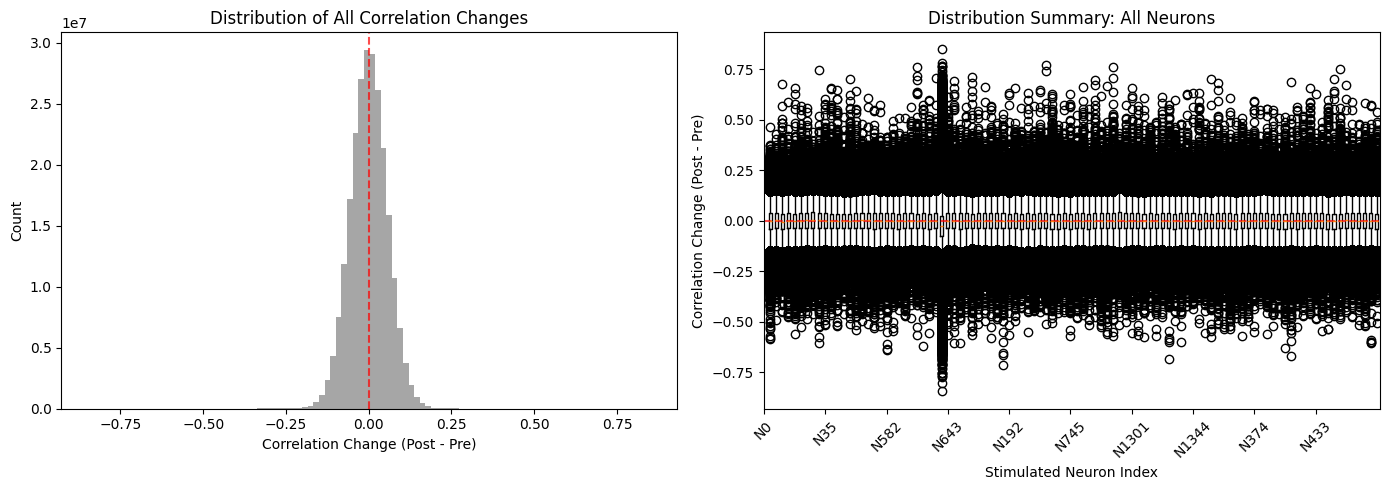

Total correlation changes analyzed: 241670100
Mean change: -0.0003
Median change: -0.0002
Standard deviation: 0.0559


In [23]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Load session data
data = load.load_session_data(session_name)  # Replace session_name with your actual session
dff_traces = data['dff_traces'] 
photostim = data['nwb_file'].stimulus["PhotostimTrials"].to_dataframe()

# Clean the data (remove NaN neurons)
nan_neurons = np.isnan(dff_traces).any(axis=0)
valid_neurons = ~nan_neurons
valid_neuron_indices = np.where(valid_neurons)[0]
dff_traces_clean = dff_traces[:, valid_neuron_indices]

# Create trial DataFrames
pre_trials = photostim[photostim['stimulus_name'] == 'photostim'].copy().reset_index(drop=True)
post_trials = photostim[photostim['stimulus_name'] == 'photostim_post'].copy().reset_index(drop=True)

# Identify common neurons
common_neurons = set(pre_trials['closest_roi']).intersection(set(post_trials['closest_roi']))

# Define correlation function
def correlation_prepost_stimulation(dff_traces_clean, pre_trials, post_trials, stimulated_neuron_id, show_plot=False):
   # Combine all pre-learning trials
   pre_data_list = []
   for _, trial in pre_trials.iterrows():
       trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
       pre_data_list.append(trial_dff)
   dff_pre = np.concatenate(pre_data_list, axis=1)
   
   # Combine all post-learning trials  
   post_data_list = []
   for _, trial in post_trials.iterrows():
       trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
       post_data_list.append(trial_dff)
   dff_post = np.concatenate(post_data_list, axis=1)
   
   # Calculate correlation matrices
   correlations_pre = np.corrcoef(dff_pre)
   correlations_post = np.corrcoef(dff_post)
   
   return correlations_pre, correlations_post, None

# Run the analysis for all neurons
stimulated_neurons = list(common_neurons)
all_correlation_changes = {}

for i, target_neuron in enumerate(stimulated_neurons):
   print(f"Processing neuron {target_neuron} ({i+1}/{len(stimulated_neurons)})")
   
   pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
   post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]
   
   correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
       dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
   
   correlation_diff = correlations_post - correlations_pre
   upper_triangle = np.triu(correlation_diff, k=1)
   all_changes = upper_triangle[upper_triangle != 0]
   all_correlation_changes[target_neuron] = all_changes

# Create plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Combined histogram of all changes
all_changes_combined = np.concatenate(list(all_correlation_changes.values()))
ax1.hist(all_changes_combined, bins=100, alpha=0.7, color='gray')
ax1.set_xlabel('Correlation Change (Post - Pre)')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of All Correlation Changes')
ax1.axvline(x=0, color='red', linestyle='--', alpha=0.7)

# Box plot for all neurons
data_for_boxplot = [changes for changes in all_correlation_changes.values()]
ax2.boxplot(data_for_boxplot)
ax2.set_xlabel('Stimulated Neuron Index')
ax2.set_ylabel('Correlation Change (Post - Pre)')
ax2.set_title('Distribution Summary: All Neurons')
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.7)

# Show fewer x-axis labels
neuron_ids = list(all_correlation_changes.keys())
ax2.set_xticks(range(0, len(neuron_ids), 10))
ax2.set_xticklabels([f'N{neuron_ids[i]}' for i in range(0, len(neuron_ids), 10)], rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics
print(f"Total correlation changes analyzed: {len(all_changes_combined)}")
print(f"Mean change: {np.mean(all_changes_combined):.4f}")
print(f"Median change: {np.median(all_changes_combined):.4f}")
print(f"Standard deviation: {np.std(all_changes_combined):.4f}")

# Everything above this is good bruh

In [18]:
# Pick the first neuron (neuron 1)
target_neuron = 1

# Get all trials where neuron 1 was stimulated
pre_neuron_trials = photostim_trials[photostim_trials['closest_roi'] == target_neuron]
post_neuron_trials = photostim_post_trials[photostim_post_trials['closest_roi'] == target_neuron]

print(f"Neuron {target_neuron}:")
print(f"  Pre-learning stimulations: {len(pre_neuron_trials)}")
print(f"  Post-learning stimulations: {len(post_neuron_trials)}")
print(f"  Pre-learning trials: {pre_neuron_trials.index.tolist()}")
print(f"  Post-learning trials: {post_neuron_trials.index.tolist()}")

Neuron 1:
  Pre-learning stimulations: 21
  Post-learning stimulations: 21
  Pre-learning trials: [61, 196, 272, 300, 498, 511, 665, 751, 818, 931, 1061, 1196, 1272, 1300, 1498, 1511, 1665, 1751, 1818, 1931, 2061]
  Post-learning trials: [61, 196, 272, 300, 498, 511, 665, 751, 818, 931, 1061, 1196, 1272, 1300, 1498, 1511, 1665, 1751, 1818, 1931, 2061]


In [19]:
# Load the full session (the parent session that contains all trials)
full_session_data = load.load_session_data(sesh_zero)
print(f"Loaded session: {sesh_zero}")
print(f"Available keys: {list(full_session_data.keys())}")

# Check the shape of the neural activity data
dff_traces = full_session_data['dff_traces']
print(f"Full session dff_traces shape: {dff_traces.shape}")

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_767715_2025-02-17_17-41-50_processed_2025-08-05_01-05-20

NWB file: single-plane-ophys_767715_2025-02-17_17-41-50_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_767715_2025-02-17_17-41-50_processed_2025-08-05_01-05-20/single-plane-ophys_767715_2025-02-17_17-41-50_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 767715: ['single-plane-ophys_767715_2025-02-10', 'single-plane-ophys_767715_2025-02-03', 'single-plane-ophys_767715_2025-01-31', 'single-plane-ophys_767715_2025-02-06', 'single-plane-ophys_767715_2025-02-17', 'single-plane-ophys_767715_2025-02-13']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_767715_2025-02-17
total difference in dataframes: 4
Loaded session: single-plane-ophys_767715_2025-02-17_17-41-50_processed_2025-08-05_01-05-20
Available keys: ['nwb_file', 'epoch_table', 'dff_traces', 'roi_table', 'frame_rate', 'bci_trials', 'thresholds']
Full session dff_traces shape: (238556, 2312)


In [20]:
# For neuron 1, first pre-learning trial:
trial_info = pre_neuron_trials.iloc[0]
start_frame = trial_info['start_frame'] 
stop_frame = trial_info['stop_frame']

print(f"Trial info:")
print(f"  Tiff file: {trial_info['tiff_file']}")
print(f"  Frames: {start_frame} to {stop_frame}")
print(f"  Duration: {stop_frame - start_frame} frames")

# Extract neural activity for this specific trial
trial_dff = dff_traces[start_frame:stop_frame, :]
print(f"Trial dff shape: {trial_dff.shape}")
print(f"This trial captured activity from {trial_dff.shape[1]} neurons for {trial_dff.shape[0]} frames")

Trial info:
  Tiff file: spont_slm_00062.tif
  Frames: 2247 to 2284
  Duration: 37 frames
Trial dff shape: (37, 2312)
This trial captured activity from 2312 neurons for 37 frames


In [21]:
def get_trial_correlations(trial_list, dff_traces):
    """Calculate correlation matrix for a set of trials"""
    all_trial_data = []
    
    for _, trial in trial_list.iterrows():
        start_frame = trial['start_frame']
        stop_frame = trial['stop_frame']
        trial_dff = dff_traces[start_frame:stop_frame, :].T  # Transpose so neurons are rows
        all_trial_data.append(trial_dff)
    
    # Concatenate all trials along time dimension
    combined_data = np.concatenate(all_trial_data, axis=1)
    
    # Calculate correlation matrix (neurons x neurons)
    correlation_matrix = np.corrcoef(combined_data)
    
    return correlation_matrix

# Calculate correlations for neuron 1 stimulation trials
pre_correlations = get_trial_correlations(pre_neuron_trials, dff_traces)
post_correlations = get_trial_correlations(post_neuron_trials, dff_traces)

print(f"Pre-learning correlation matrix shape: {pre_correlations.shape}")
print(f"Post-learning correlation matrix shape: {post_correlations.shape}")

# Calculate the difference
correlation_diff = post_correlations - pre_correlations
print(f"Correlation difference matrix shape: {correlation_diff.shape}")

Pre-learning correlation matrix shape: (2312, 2312)
Post-learning correlation matrix shape: (2312, 2312)
Correlation difference matrix shape: (2312, 2312)


In [22]:
photostim_neurons = photostim.closest_roi.unique()
#photostim_neurons

In [23]:
photostim_neurons

array([  27,  284,   48,  130,  549,  789,    3, 2185,  622,    8,  571,
        376,  310,  123,  433,  113,  495,  955, 1072,   17,  244,   92,
        127,  101,  104,   82,  643,    2,   61,  292,  178,   97,   74,
         11,  303,  265,  540,  233,   62,  107,  174,  171, 1287,  117,
        103,   40,   68,  502,  959,   16,  402,  464,  102,  324,  263,
         91,  146,  256,  385,  255,   19,    1,   47, 1910, 1579,  106,
        268,   50, 1392,  579,  750,  186, 1673,  135,   55,  841,  173,
       1997,   53,  384,    4,  609,   23,  213,   99,   25,  100,  152,
        763, 1342,  417,  588,  892,   75,  153,  443,  208,  253,   70,
        148])

In [24]:
# Start with the first neuron of this one trial
photo_test = photostim[photostim["closest_roi"] == photostim_neurons[0]]

In [25]:
photo_test

,start_time,stop_time,start_frame,stop_frame,tiff_file,stimulus_name,laser_x,laser_y,power,duration,stimulus_function,group_index,closest_roi
id,,,,,,,,,,,,,
0,0.000000,0.618231,0,36,spont_slm_00001.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
137,88.218071,88.853474,5137,5174,spont_slm_00138.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
251,162.611818,163.230049,9469,9505,spont_slm_00252.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
394,252.839138,253.440196,14723,14758,spont_slm_00395.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
405,259.828578,260.412463,15130,15164,spont_slm_00406.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
523,333.861692,334.445576,19441,19475,spont_slm_00524.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
608,386.754753,387.372984,22521,22557,spont_slm_00609.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
761,482.700706,483.336110,28108,28145,spont_slm_00762.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27
886,561.095779,561.696837,32673,32708,spont_slm_00887.tif,photostim,471.492308,136.076923,2,0.062,scanimage.mroi.stimulusfunctions.logspiral,50,27


In [26]:
# Call in the epoch table
epoch_table = data['epoch_table']

# This will pull the photostim and photostim_post stimuli only and add a new column (duration)
relevant_epochs = epoch_table[epoch_table['stimulus_name'].isin(photo_test['stimulus_name'])].copy()
relevant_epochs['duration'] = relevant_epochs.stop_time-relevant_epochs.start_time


In [27]:
valid_roi_table, cn_index = processing.filter_somas(data=data)
#valid_roi_table

CN: [48]


In [28]:
relevant_epochs

,stimulus_name,start_frame,stop_frame,start_time,stop_time,duration
id,,,,,,
0,photostim,0,76291,0.000000,1310.150831,1310.150831
4,photostim_post,159934,238555,2746.558087,4096.722176,1350.164089


In [29]:
relevant_epochs.stimulus_name.unique()

array(['photostim', 'photostim_post'], dtype=object)

In [30]:
# You have to unpack the variables in order to be able to use them
photostim_pre_start, photostim_pre_stop, photostim_post_start, photostim_post_stop = photostim_prepost_frames(epoch_table)

In [31]:
dff_traces = data['dff_traces']

dff_pre shape: (472, 76291)
dff_post shape: (472, 78621)
T-test p-value: 5.051382643848072e-138


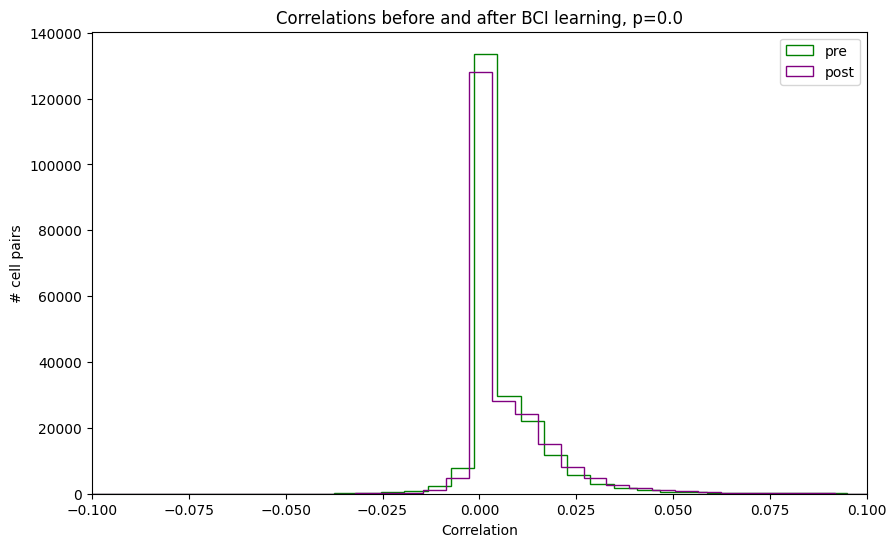

In [32]:
correlations_pre, correlations_post, p_val = correlation_prepost_bci(
    dff_traces, 
    photostim_pre_start, 
    photostim_pre_stop, 
    photostim_post_start, 
    photostim_post_stop, 
    valid_roi_table
)

In [33]:
# Calculate centroids for each ROI 
centroids = get_roi_centroids(valid_roi_table)
centroidX = centroids[:, 0]
centroidY = centroids[:, 1]

In [34]:
centroid_cell_1 = centroids[0, :]
centroid_cell_2 = centroids[1, :]

math.dist(centroid_cell_1, centroid_cell_2)

55.51808732418818

In [35]:
pairs_data = []
for roi_id_1 in range(len(valid_roi_table.index.values)): 
    for roi_id_2 in range(len(valid_roi_table.index.values)): 
        centroid_cell_1 = centroids[roi_id_1, :]
        centroid_cell_2 = centroids[roi_id_2, :]
        distance = math.dist(centroid_cell_1, centroid_cell_2)
        r_value_pre = correlations_pre[roi_id_1, roi_id_2]
        r_value_post = correlations_post[roi_id_1, roi_id_2]
        r_value_diff = r_value_post-r_value_pre
        pairs_data.append([roi_id_1, roi_id_2, r_value_pre, r_value_post, r_value_diff, distance])

In [36]:
pairs = pd.DataFrame(pairs_data, columns=['roi_id_1', 'roi_id_2', 'r_value_pre', 'r_value_post', 'r_value_diff', 'distance'])
pairs.head()

,roi_id_1,roi_id_2,r_value_pre,r_value_post,r_value_diff,distance
0,0,0,0.000000,0.000000,0.000000,0.000000
1,0,1,-0.001192,-0.015556,-0.014363,55.518087
2,0,2,0.007820,-0.000821,-0.008641,140.101732
3,0,3,0.009756,-0.002105,-0.011861,126.558612
4,0,4,0.028154,0.002095,-0.026059,180.181381


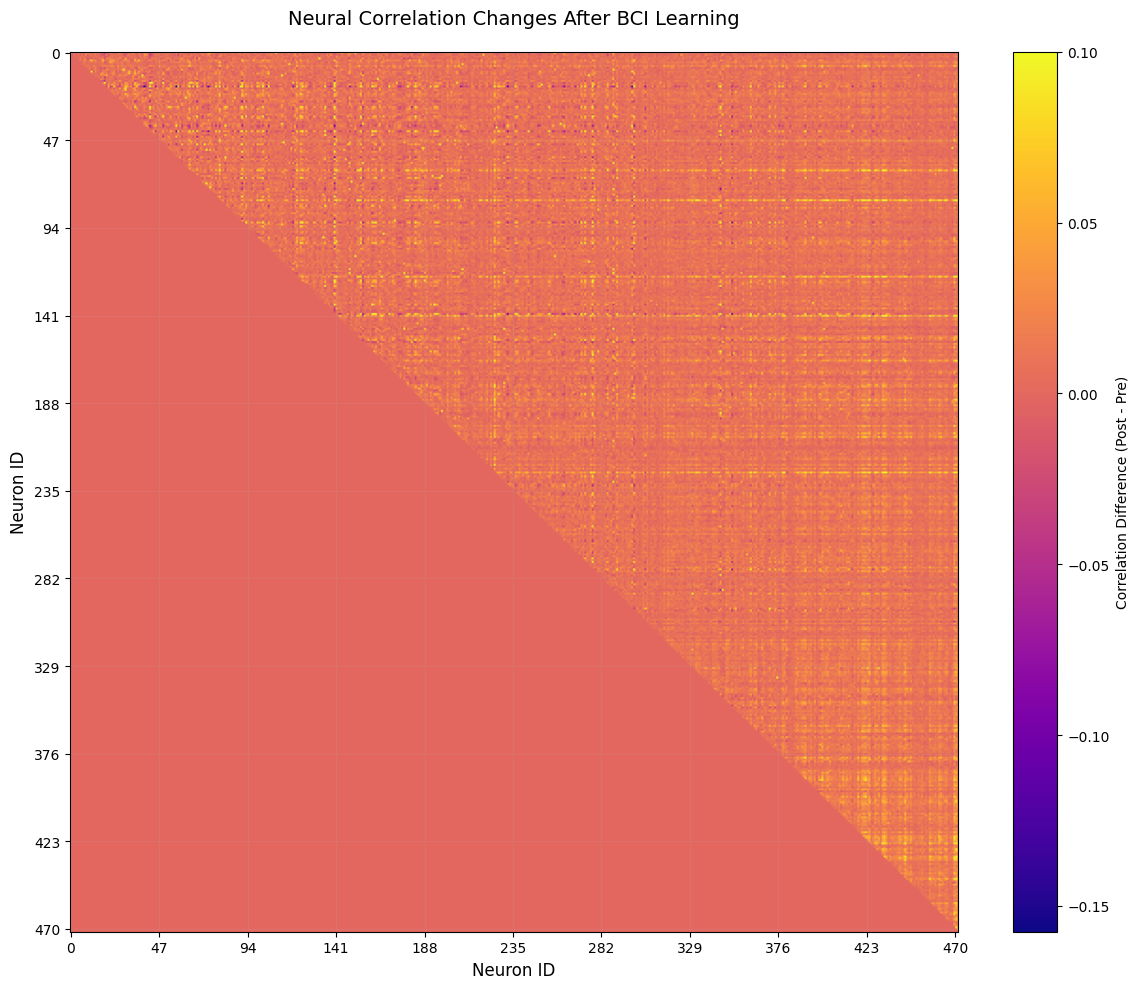

In [37]:
# Create pivot table for heatmap
heatmap_data = pairs.pivot(index='roi_id_1', columns='roi_id_2', values='r_value_pre')

# Create heatmap
plt.figure(figsize=(12, 10))
im = plt.imshow(heatmap_data, cmap='plasma', vmax = 0.1, aspect='auto')
cbar = plt.colorbar(im, label='Correlation Difference (Post - Pre)')

# Set cleaner tick spacing - show every 5th or 10th neuron
step = max(1, len(heatmap_data) // 10)  # Adjust density automatically
x_ticks = range(0, len(heatmap_data.columns), step)
y_ticks = range(0, len(heatmap_data.index), step)

plt.xticks(x_ticks, [heatmap_data.columns[i] for i in x_ticks])
plt.yticks(y_ticks, [heatmap_data.index[i] for i in y_ticks])

plt.title('Neural Correlation Changes After BCI Learning', fontsize=14, pad=20)
plt.xlabel('Neuron ID', fontsize=12)
plt.ylabel('Neuron ID', fontsize=12)

# Add subtle grid for easier reading
plt.grid(True, alpha=0.2, linewidth=0.5)
plt.tight_layout()
plt.show()

In [38]:
# Select the top 2000 gene pairs with the largest absolute differences in correlation
# between conditions, while preserving the original signed values in r_value_diff.
# This sorts by absolute magnitude but keeps both positive and negative differences.
top_n = 2000
top_pairs = pairs.reindex(pairs['r_value_diff'].abs().sort_values(ascending=False).index).head(top_n)

Text(0.5, 1.0, 'Activity correlation as a function of distance for top 2000 cell pairs')

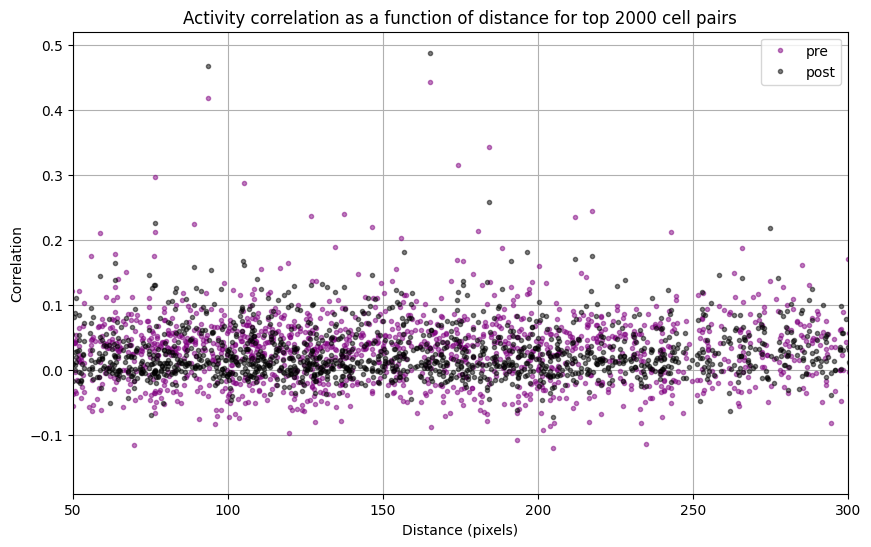

In [39]:
plt.figure(figsize=(10, 6))
#plt.plot(top_pairs.distance.values, filtered_pairs.r_value_diff, '.', color='green', label='pre', alpha=0.5)
plt.plot(top_pairs.distance.values, top_pairs.r_value_pre.values, '.', color='purple', label='pre', alpha=0.5)
#plt.plot(top_pairs.distance.values, top_pairs.r_value_post_values, '.', color='black', label='diff', alpha=0.5)
plt.plot(top_pairs.distance.values, top_pairs.r_value_post.values, '.', color='black', label='post', alpha=0.5)

plt.legend()
plt.ylabel('Correlation')
plt.xlabel('Distance (pixels)')
plt.xlim(50, 300)
plt.grid(True)
plt.title('Activity correlation as a function of distance for top 2000 cell pairs')

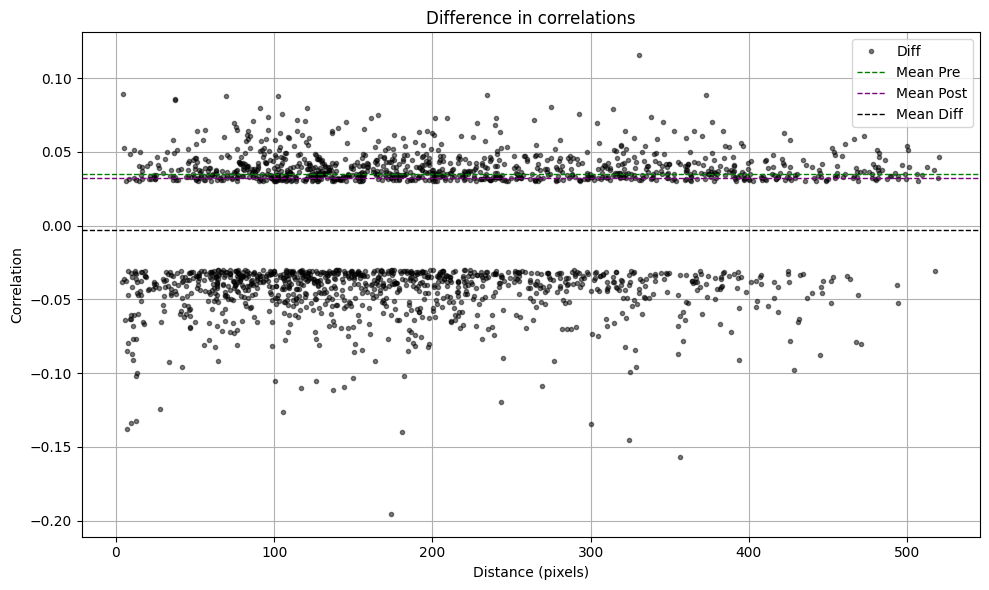

In [40]:
# Compute means
mean_pre = top_pairs.r_value_pre.mean()
mean_post = top_pairs.r_value_post.mean()
mean_diff = top_pairs.r_value_diff.mean()

plt.figure(figsize=(10, 6))

# Scatter plots
#plt.plot(top_pairs.distance.values, top_pairs.r_value_pre.values, '.', color='green', label='Pre', alpha=0.5)
#plt.plot(top_pairs.distance.values, top_pairs.r_value_post.values, '.', color='purple', label='Post', alpha=0.5)
plt.plot(top_pairs.distance.values, top_pairs.r_value_diff.values, '.', color='black', label='Diff', alpha=0.5)

# Horizontal mean lines
plt.axhline(mean_pre, color='green', linestyle='--', linewidth=1, label='Mean Pre')
plt.axhline(mean_post, color='purple', linestyle='--', linewidth=1, label='Mean Post')
plt.axhline(mean_diff, color='black', linestyle='--', linewidth=1, label='Mean Diff')

# Labels
plt.legend()
plt.ylabel('Correlation')
plt.xlabel('Distance (pixels)')
plt.title('Difference in correlations')
plt.grid(True)
plt.tight_layout()
plt.show()


In [41]:
# Define thresholds for meaningful changes
small_threshold = 0.01   # Small but detectable change
large_threshold = 0.05   # Large change

# Count changes by magnitude
small_changes = np.abs(unique_changes) > small_threshold
large_changes = np.abs(unique_changes) > large_threshold

print(f"Pairs with small changes (>0.01): {small_changes.sum()}")
print(f"Pairs with large changes (>0.05): {large_changes.sum()}")
print(f"Percentage with meaningful changes: {100 * small_changes.sum() / len(unique_changes):.1f}%")

NameError: name 'unique_changes' is not defined

In [42]:
def correlation_prepost_stimulation(dff_traces_clean, pre_trials, post_trials, stimulated_neuron_id):
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    
    # Combine all pre-learning trials
    pre_data_list = []
    for _, trial in pre_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        pre_data_list.append(trial_dff)
    dff_pre = np.concatenate(pre_data_list, axis=1)
    
    # Combine all post-learning trials  
    post_data_list = []
    for _, trial in post_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        post_data_list.append(trial_dff)
    dff_post = np.concatenate(post_data_list, axis=1)
    
    print(f"dff_pre shape: {dff_pre.shape}")
    print(f"dff_post shape: {dff_post.shape}")
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    # Keep only upper triangular part (avoid duplicate pairs and diagonal)
    correlations_pre_upper = np.triu(correlations_pre, k=1)
    correlations_post_upper = np.triu(correlations_post, k=1)
    
    # Statistical comparison
    t, p_val = stats.ttest_ind(correlations_pre_upper.flatten(), correlations_post_upper.flatten())
    print(f"T-test p-value: {p_val}")
    
    # Plot both distributions
    plt.figure(figsize=(10, 6))
    plt.hist(correlations_pre_upper.flatten(), bins=100, color='green', label='pre', histtype='step')
    plt.hist(correlations_post_upper.flatten(), bins=100, color='purple', label='post', histtype='step')
    plt.title(f'Correlations before and after BCI learning (Neuron {stimulated_neuron_id} stimulation), p=' + str(np.round(p_val, 5)))
    plt.xlabel('Correlation')
    plt.ylabel('# cell pairs')
    plt.xlim(-0.1, 0.1)
    plt.legend()
    plt.show()
    
    return correlations_pre, correlations_post, p_val


Total neurons: 2312
Neurons with NaN: 76
Valid neurons: 2236
Clean dff_traces shape: (238556, 2236)
dff_pre shape: (2236, 757)
dff_post shape: (2236, 749)
T-test p-value: 0.0


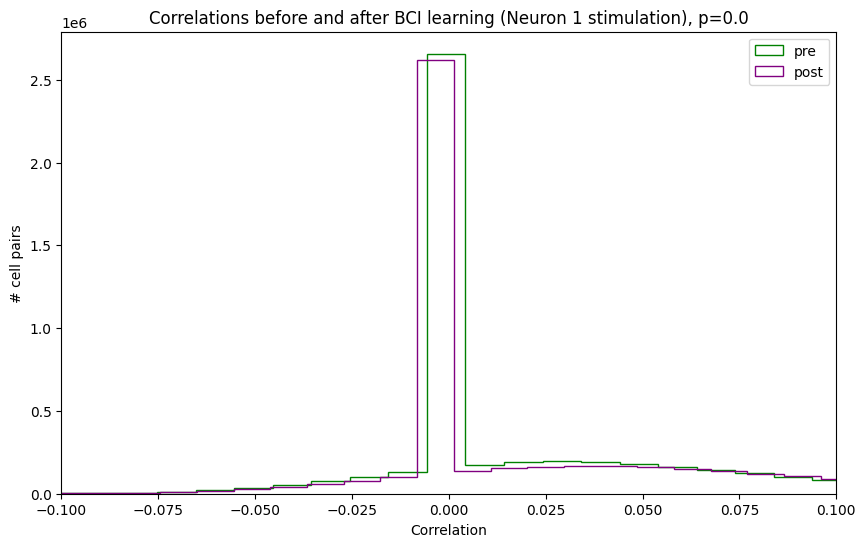

In [43]:
# Create the clean dataset using proper indexing
nan_neurons = np.isnan(dff_traces).any(axis=0)
valid_neurons = ~nan_neurons

print(f"Total neurons: {dff_traces.shape[1]}")
print(f"Neurons with NaN: {nan_neurons.sum()}")
print(f"Valid neurons: {valid_neurons.sum()}")

# Use np.where to get integer indices instead of boolean array
valid_neuron_indices = np.where(valid_neurons)[0]
dff_traces_clean = dff_traces[:, valid_neuron_indices]
print(f"Clean dff_traces shape: {dff_traces_clean.shape}")

# Now run the correlation function:
correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
    dff_traces_clean, 
    pre_neuron_trials, 
    post_neuron_trials, 
    stimulated_neuron_id=1
)

Mean correlation change: 0.013226
Std of changes: 0.060837
Biggest increase: 0.4580
Biggest decrease: -0.4738


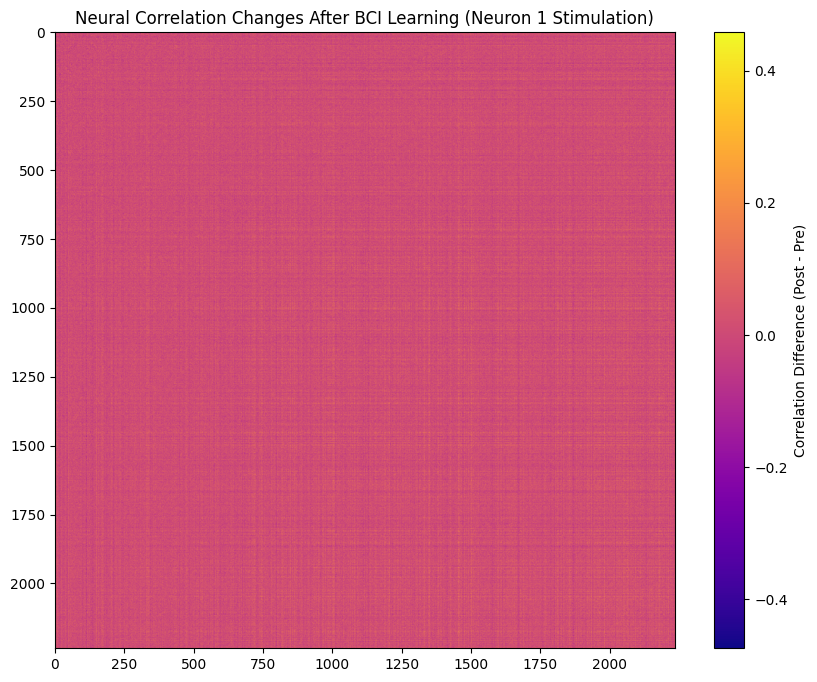

In [44]:
# Calculate correlation differences for neuron 1
correlation_diff = correlations_post - correlations_pre

# Get upper triangle to avoid duplicates
upper_mask = np.triu(np.ones_like(correlation_diff), k=1).astype(bool)
unique_changes = correlation_diff[upper_mask]

# Summary statistics
print(f"Mean correlation change: {unique_changes.mean():.6f}")
print(f"Std of changes: {unique_changes.std():.6f}")
print(f"Biggest increase: {unique_changes.max():.4f}")
print(f"Biggest decrease: {unique_changes.min():.4f}")

# Create the heatmap
plt.figure(figsize=(10, 8))
plt.imshow(correlation_diff, cmap='plasma', aspect='auto')
plt.colorbar(label='Correlation Difference (Post - Pre)')
plt.title(f'Neural Correlation Changes After BCI Learning (Neuron 1 Stimulation)')
plt.show()

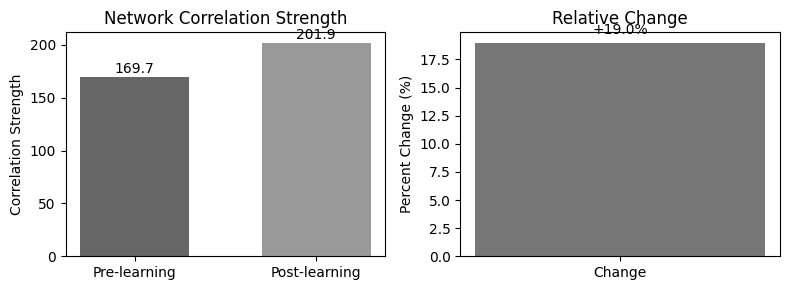

Pre-learning correlation strength: 169.69
Post-learning correlation strength: 201.88
Percent change: +18.97%


In [45]:
# Calculate norms
pre_norm = np.linalg.norm(correlations_pre, 'fro')
post_norm = np.linalg.norm(correlations_post, 'fro')
norm_change = post_norm - pre_norm
percent_change = 100 * norm_change / pre_norm

# Create simple visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3))

# Panel A: Before/After comparison
bars = ax1.bar(['Pre-learning', 'Post-learning'], [pre_norm, post_norm], 
               color=['#666666', '#999999'], width=0.6)
ax1.set_ylabel('Correlation Strength')
ax1.set_title('Network Correlation Strength')

# Panel B: Percent change
ax2.bar(['Change'], [percent_change], color='#777777', width=0.4)
ax2.set_ylabel('Percent Change (%)')
ax2.set_title('Relative Change')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

# Add value annotations
for i, (bar, value) in enumerate(zip(bars, [pre_norm, post_norm])):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
             f'{value:.1f}', ha='center', va='bottom')

ax2.text(0, percent_change + (0.5 if percent_change > 0 else -0.5), 
         f'{percent_change:+.1f}%', ha='center', va='bottom' if percent_change > 0 else 'top')

plt.tight_layout()
plt.show()

print(f"Pre-learning correlation strength: {pre_norm:.2f}")
print(f"Post-learning correlation strength: {post_norm:.2f}")
print(f"Percent change: {percent_change:+.2f}%")

In [46]:
# Recreate the pre and post trial datasets
pre_trials = photostim[photostim['stimulus_name'] == 'photostim'].copy().reset_index(drop=True)
post_trials = photostim[photostim['stimulus_name'] == 'photostim_post'].copy().reset_index(drop=True)

print(f"Pre-learning trials: {len(pre_trials)}")
print(f"Post-learning trials: {len(post_trials)}")

# Also recreate the common neurons list
pre_neurons = set(pre_trials['closest_roi'])
post_neurons = set(post_trials['closest_roi'])
common_neurons = pre_neurons.intersection(post_neurons)

print(f"Neurons stimulated in both phases: {len(common_neurons)}")

Pre-learning trials: 2064
Post-learning trials: 2140
Neurons stimulated in both phases: 100


Pre-learning trials: 2064
Post-learning trials: 2140
Neurons stimulated in both phases: 100

Analyzing correlation changes across neurons:
dff_pre shape: (2236, 757)
dff_post shape: (2236, 749)
T-test p-value: 0.0


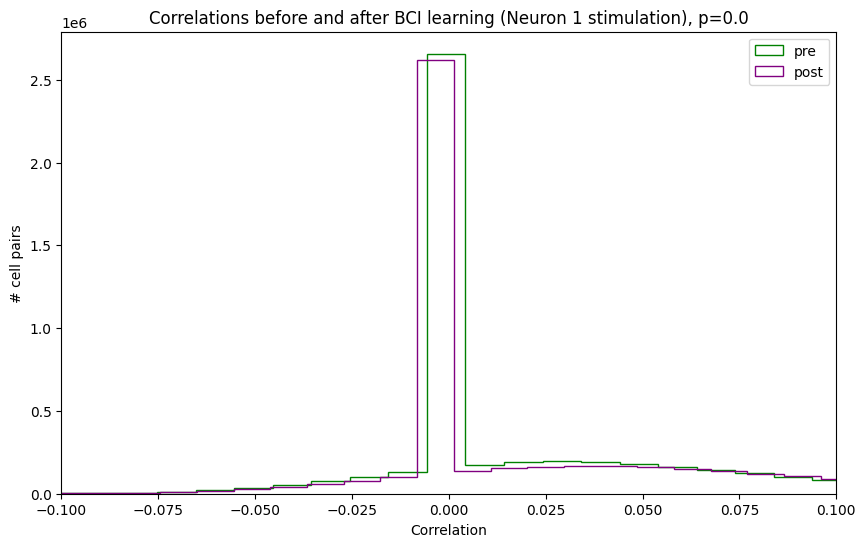

Neuron 1: +19.0% change (p=0.0000)
dff_pre shape: (2236, 745)
dff_post shape: (2236, 758)
T-test p-value: 1.444680513517946e-56


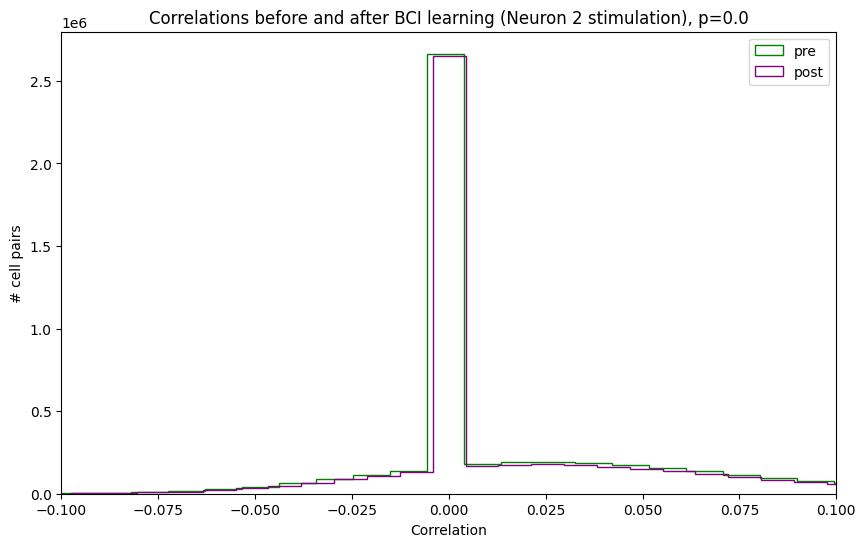

Neuron 2: -3.0% change (p=0.0000)
dff_pre shape: (2236, 755)
dff_post shape: (2236, 785)
T-test p-value: 0.0


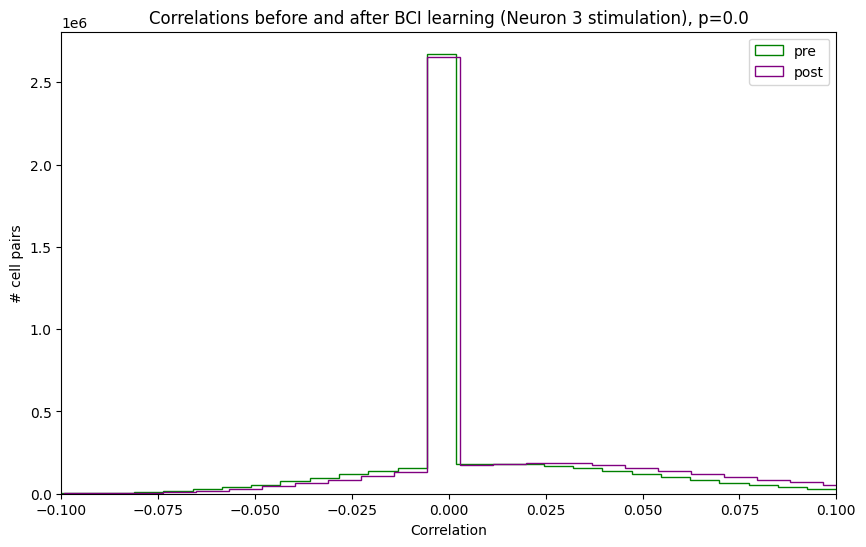

Neuron 3: +26.1% change (p=0.0000)
dff_pre shape: (2236, 710)
dff_post shape: (2236, 744)
T-test p-value: 0.0


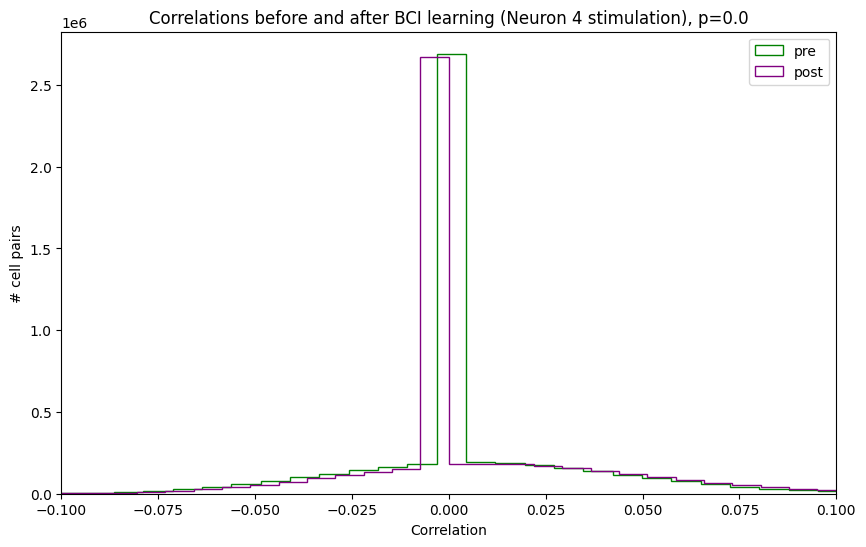

Neuron 4: +6.2% change (p=0.0000)
dff_pre shape: (2236, 742)
dff_post shape: (2236, 757)
T-test p-value: 0.0


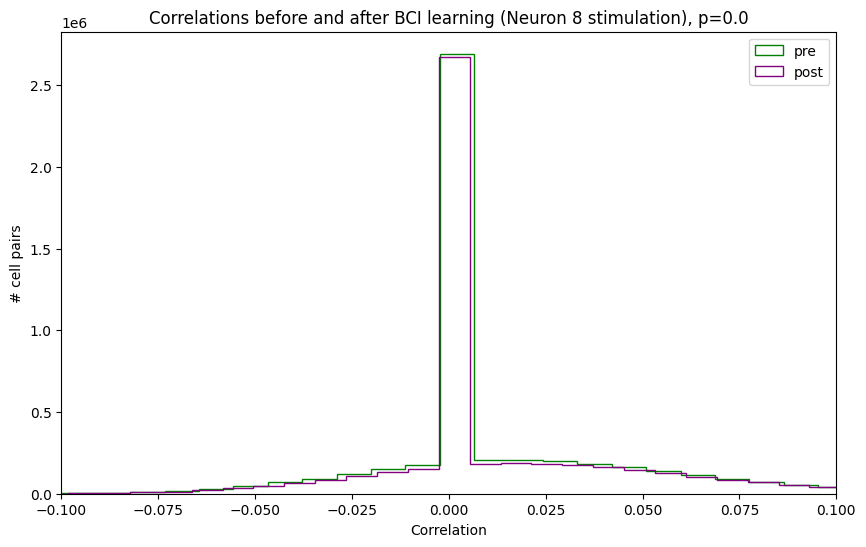

Neuron 8: +1.1% change (p=0.0000)

Pattern analysis complete!


In [47]:
# Create pre and post trial datasets
pre_trials = photostim[photostim['stimulus_name'] == 'photostim'].copy().reset_index(drop=True)
post_trials = photostim[photostim['stimulus_name'] == 'photostim_post'].copy().reset_index(drop=True)

print(f"Pre-learning trials: {len(pre_trials)}")
print(f"Post-learning trials: {len(post_trials)}")

# Get neurons stimulated in both phases
common_neurons = set(pre_trials['closest_roi']).intersection(set(post_trials['closest_roi']))
print(f"Neurons stimulated in both phases: {len(common_neurons)}")

# Analyze first 5 neurons for patterns
neuron_results = {}
print("\nAnalyzing correlation changes across neurons:")

for neuron_id in list(common_neurons)[:5]:
    pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == neuron_id]
    post_neuron_trials = post_trials[post_trials['closest_roi'] == neuron_id]
    
    correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, neuron_id)
    
    # Calculate correlation strength changes
    pre_norm = np.linalg.norm(correlations_pre, 'fro')
    post_norm = np.linalg.norm(correlations_post, 'fro')
    percent_change = 100 * (post_norm - pre_norm) / pre_norm
    
    neuron_results[neuron_id] = {
        'percent_change': percent_change,
        'p_value': p_val
    }
    
    print(f"Neuron {neuron_id}: {percent_change:+.1f}% change (p={p_val:.4f})")

print("\nPattern analysis complete!")

In [48]:
def correlation_prepost_stimulation(dff_traces_clean, pre_trials, post_trials, stimulated_neuron_id, show_plot=False):
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats
    
    # Combine all pre-learning trials
    pre_data_list = []
    for _, trial in pre_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        pre_data_list.append(trial_dff)
    dff_pre = np.concatenate(pre_data_list, axis=1)
    
    # Combine all post-learning trials  
    post_data_list = []
    for _, trial in post_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        post_data_list.append(trial_dff)
    dff_post = np.concatenate(post_data_list, axis=1)
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    # Keep only upper triangular part (avoid duplicate pairs and diagonal)
    correlations_pre_upper = np.triu(correlations_pre, k=1)
    correlations_post_upper = np.triu(correlations_post, k=1)
    
    # Statistical comparison
    t, p_val = stats.ttest_ind(correlations_pre_upper.flatten(), correlations_post_upper.flatten())
    
    # Only plot if requested
    if show_plot:
        plt.figure(figsize=(10, 6))
        plt.hist(correlations_pre_upper.flatten(), bins=100, color='green', label='pre', histtype='step')
        plt.hist(correlations_post_upper.flatten(), bins=100, color='purple', label='post', histtype='step')
        plt.title(f'Correlations before and after BCI learning (Neuron {stimulated_neuron_id} stimulation), p=' + str(np.round(p_val, 5)))
        plt.xlabel('Correlation')
        plt.ylabel('# cell pairs')
        plt.xlim(-0.1, 0.1)
        plt.legend()
        plt.show()
    
    return correlations_pre, correlations_post, p_val

Analyzing correlation changes across neurons:
Neuron 1: +19.0% change
Neuron 2: -3.0% change
Neuron 3: +26.1% change
Neuron 4: +6.2% change
Neuron 8: +1.1% change


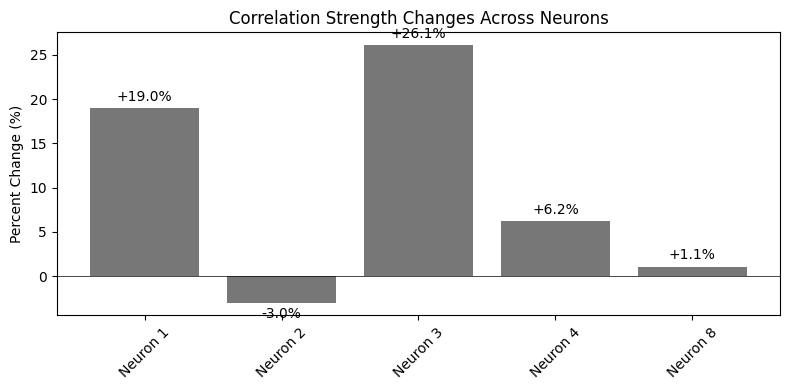

In [49]:
# Create pre and post trial datasets
pre_trials = photostim[photostim['stimulus_name'] == 'photostim'].copy().reset_index(drop=True)
post_trials = photostim[photostim['stimulus_name'] == 'photostim_post'].copy().reset_index(drop=True)

# Get neurons stimulated in both phases
common_neurons = set(pre_trials['closest_roi']).intersection(set(post_trials['closest_roi']))

# Analyze first 5 neurons without individual plots
neuron_results = {}
print("Analyzing correlation changes across neurons:")

for neuron_id in list(common_neurons)[:5]:
    pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == neuron_id]
    post_neuron_trials = post_trials[post_trials['closest_roi'] == neuron_id]
    
    correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, neuron_id, show_plot=False)
    
    # Calculate changes
    pre_norm = np.linalg.norm(correlations_pre, 'fro')
    post_norm = np.linalg.norm(correlations_post, 'fro')
    percent_change = 100 * (post_norm - pre_norm) / pre_norm
    
    neuron_results[neuron_id] = percent_change
    print(f"Neuron {neuron_id}: {percent_change:+.1f}% change")

# Create one combined graph
neuron_ids = list(neuron_results.keys())
percent_changes = list(neuron_results.values())

plt.figure(figsize=(8, 4))
bars = plt.bar([f'Neuron {nid}' for nid in neuron_ids], percent_changes, color='#777777')
plt.ylabel('Percent Change (%)')
plt.title('Correlation Strength Changes Across Neurons')
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

# Add value annotations
for bar, value in zip(bars, percent_changes):
    plt.text(bar.get_x() + bar.get_width()/2, value + (0.5 if value > 0 else -0.5),
             f'{value:+.1f}%', ha='center', va='bottom' if value > 0 else 'top')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

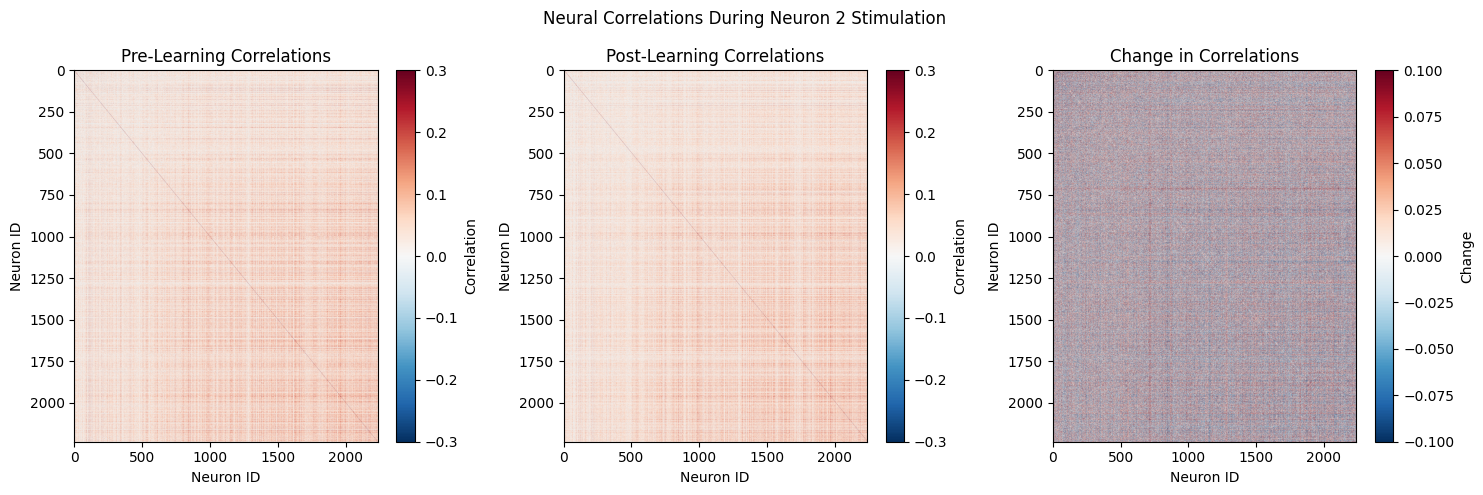

Analyzing correlations when neuron 2 was stimulated
Matrix size: 2236 x 2236 neurons


In [50]:
# Pick one neuron to analyze (let's use neuron 1 as we did before)
target_neuron = list(common_neurons)[1]
pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]

# Get the full correlation matrices (not just upper triangle)
correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
    dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)

# Create side-by-side heatmaps
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))

# Pre-learning correlations
im1 = ax1.imshow(correlations_pre, cmap='RdBu_r', vmin=-0.3, vmax=0.3, aspect='auto')
ax1.set_title('Pre-Learning Correlations')
ax1.set_xlabel('Neuron ID')
ax1.set_ylabel('Neuron ID')

# Post-learning correlations  
im2 = ax2.imshow(correlations_post, cmap='RdBu_r', vmin=-0.3, vmax=0.3, aspect='auto')
ax2.set_title('Post-Learning Correlations')
ax2.set_xlabel('Neuron ID')
ax2.set_ylabel('Neuron ID')

# Difference (Post - Pre)
correlation_diff = correlations_post - correlations_pre
im3 = ax3.imshow(correlation_diff, cmap='RdBu_r', vmin=-0.1, vmax=0.1, aspect='auto')
ax3.set_title('Change in Correlations')
ax3.set_xlabel('Neuron ID')
ax3.set_ylabel('Neuron ID')

# Add colorbars
plt.colorbar(im1, ax=ax1, label='Correlation')
plt.colorbar(im2, ax=ax2, label='Correlation') 
plt.colorbar(im3, ax=ax3, label='Change')

plt.suptitle(f'Neural Correlations During Neuron {target_neuron} Stimulation')
plt.tight_layout()
plt.show()

print(f"Analyzing correlations when neuron {target_neuron} was stimulated")
print(f"Matrix size: {correlations_pre.shape[0]} x {correlations_pre.shape[1]} neurons")

In [51]:
# Extract specific insights from the heatmap
correlation_diff = correlations_post - correlations_pre

# Find the biggest changes
upper_triangle = np.triu(correlation_diff, k=1)
max_increase_idx = np.unravel_index(np.argmax(upper_triangle), upper_triangle.shape)
max_decrease_idx = np.unravel_index(np.argmin(upper_triangle), upper_triangle.shape)

print(f"Biggest correlation increase: {correlation_diff[max_increase_idx]:.4f}")
print(f"Biggest correlation decrease: {correlation_diff[max_decrease_idx]:.4f}")
print(f"Number of meaningful changes (>0.01): {np.sum(np.abs(upper_triangle) > 0.01)}")

Biggest correlation increase: 0.3767
Biggest correlation decrease: -0.4954
Number of meaningful changes (>0.01): 2156781


Max increase: Neurons 1500 & 1592 = 0.3767
Max decrease: Neurons 47 & 67 = -0.4954


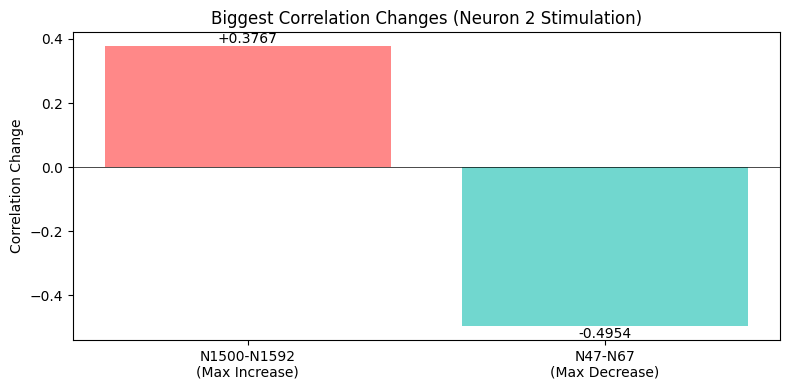

In [52]:
# Find the locations of max increase and decrease
correlation_diff = correlations_post - correlations_pre
upper_triangle = np.triu(correlation_diff, k=1)

# Get indices of max changes
max_increase_idx = np.unravel_index(np.argmax(upper_triangle), upper_triangle.shape)
max_decrease_idx = np.unravel_index(np.argmin(upper_triangle), upper_triangle.shape)

max_increase_value = correlation_diff[max_increase_idx]
max_decrease_value = correlation_diff[max_decrease_idx]

print(f"Max increase: Neurons {max_increase_idx[0]} & {max_increase_idx[1]} = {max_increase_value:.4f}")
print(f"Max decrease: Neurons {max_decrease_idx[0]} & {max_decrease_idx[1]} = {max_decrease_value:.4f}")

# Create a simple bar plot showing just these pairs
fig, ax = plt.subplots(figsize=(8, 4))

pairs = [f'N{max_increase_idx[0]}-N{max_increase_idx[1]}\n(Max Increase)', 
         f'N{max_decrease_idx[0]}-N{max_decrease_idx[1]}\n(Max Decrease)']
values = [max_increase_value, max_decrease_value]
colors = ['#FF6B6B', '#4ECDC4']  # Red for increase, teal for decrease

bars = ax.bar(pairs, values, color=colors, alpha=0.8)
ax.set_ylabel('Correlation Change')
ax.set_title(f'Biggest Correlation Changes (Neuron {target_neuron} Stimulation)')
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)

# Add value annotations
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, value + (0.002 if value > 0 else -0.002),
            f'{value:+.4f}', ha='center', va='bottom' if value > 0 else 'top')

plt.tight_layout()
plt.show()

In [53]:
# Analyze max changes across multiple stimulated neurons
all_neuron_analysis = {}

print("Analyzing max correlation changes across different stimulated neurons:")
print("-" * 70)

for i, target_neuron in enumerate(list(common_neurons)[:5]):  # Test first 5 neurons
    print(f"\nStimulated Neuron {target_neuron}:")
    
    # Get trials for this neuron
    pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
    post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]
    
    # Calculate correlations
    correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
    
    # Find max changes
    correlation_diff = correlations_post - correlations_pre
    upper_triangle = np.triu(correlation_diff, k=1)
    
    max_increase_idx = np.unravel_index(np.argmax(upper_triangle), upper_triangle.shape)
    max_decrease_idx = np.unravel_index(np.argmin(upper_triangle), upper_triangle.shape)
    
    max_increase_value = correlation_diff[max_increase_idx]
    max_decrease_value = correlation_diff[max_decrease_idx]
    
    # Store results
    all_neuron_analysis[target_neuron] = {
        'max_increase_pair': max_increase_idx,
        'max_increase_value': max_increase_value,
        'max_decrease_pair': max_decrease_idx,
        'max_decrease_value': max_decrease_value
    }
    
    print(f"  Max increase: Neurons {max_increase_idx[0]}-{max_increase_idx[1]} = {max_increase_value:+.4f}")
    print(f"  Max decrease: Neurons {max_decrease_idx[0]}-{max_decrease_idx[1]} = {max_decrease_value:+.4f}")

# Look for patterns
print("\n" + "="*70)
print("PATTERN ANALYSIS:")

# Check if the same pairs appear across different stimulated neurons
all_increase_pairs = [data['max_increase_pair'] for data in all_neuron_analysis.values()]
all_decrease_pairs = [data['max_decrease_pair'] for data in all_neuron_analysis.values()]

print(f"Max increase pairs: {all_increase_pairs}")
print(f"Max decrease pairs: {all_decrease_pairs}")

# Check for repeated pairs
from collections import Counter
increase_counter = Counter(all_increase_pairs)
decrease_counter = Counter(all_decrease_pairs)

print(f"\nRepeated increase pairs: {[pair for pair, count in increase_counter.items() if count > 1]}")
print(f"Repeated decrease pairs: {[pair for pair, count in decrease_counter.items() if count > 1]}")

Analyzing max correlation changes across different stimulated neurons:
----------------------------------------------------------------------

Stimulated Neuron 1:
  Max increase: Neurons 72-129 = +0.4580
  Max decrease: Neurons 113-124 = -0.4738

Stimulated Neuron 2:
  Max increase: Neurons 1500-1592 = +0.3767
  Max decrease: Neurons 47-67 = -0.4954

Stimulated Neuron 3:
  Max increase: Neurons 28-600 = +0.4218
  Max decrease: Neurons 14-71 = -0.4096

Stimulated Neuron 4:
  Max increase: Neurons 136-190 = +0.4732
  Max decrease: Neurons 13-21 = -0.3699

Stimulated Neuron 8:
  Max increase: Neurons 295-673 = +0.4627
  Max decrease: Neurons 47-96 = -0.5187

PATTERN ANALYSIS:
Max increase pairs: [(np.int64(72), np.int64(129)), (np.int64(1500), np.int64(1592)), (np.int64(28), np.int64(600)), (np.int64(136), np.int64(190)), (np.int64(295), np.int64(673))]
Max decrease pairs: [(np.int64(113), np.int64(124)), (np.int64(47), np.int64(67)), (np.int64(14), np.int64(71)), (np.int64(13), np.int64

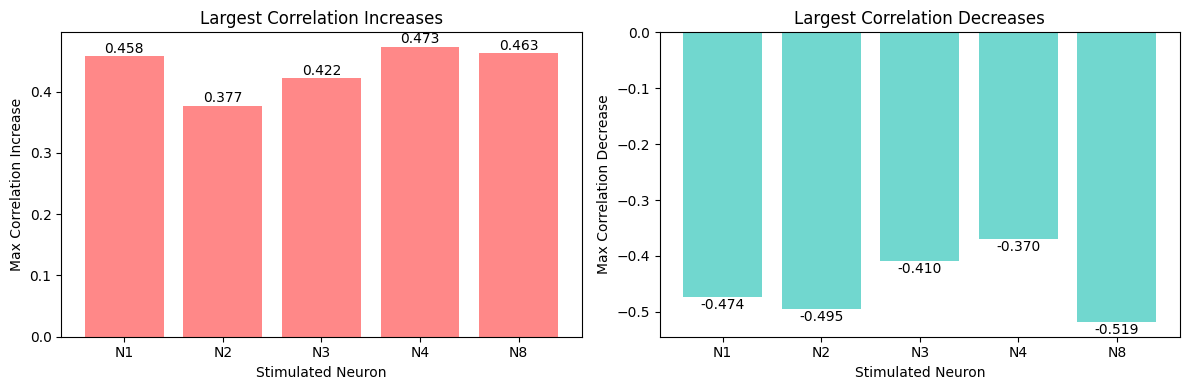

Summary:
Range of max increases: 0.377 to 0.473
Range of max decreases: -0.370 to -0.519


In [54]:
# Run the analysis and collect data for plotting
stimulated_neurons = list(common_neurons)[:5]
max_increases = []
max_decreases = []

for target_neuron in stimulated_neurons:
    pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
    post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]
    
    correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
    
    correlation_diff = correlations_post - correlations_pre
    upper_triangle = np.triu(correlation_diff, k=1)
    
    max_increases.append(np.max(upper_triangle))
    max_decreases.append(np.min(upper_triangle))

# Create the plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Max increases
ax1.bar([f'N{n}' for n in stimulated_neurons], max_increases, color='#FF6B6B', alpha=0.8)
ax1.set_ylabel('Max Correlation Increase')
ax1.set_title('Largest Correlation Increases')
ax1.set_xlabel('Stimulated Neuron')

# Add value labels
for i, v in enumerate(max_increases):
    ax1.text(i, v + 0.001, f'{v:.3f}', ha='center', va='bottom')

# Max decreases
ax2.bar([f'N{n}' for n in stimulated_neurons], max_decreases, color='#4ECDC4', alpha=0.8)
ax2.set_ylabel('Max Correlation Decrease')
ax2.set_title('Largest Correlation Decreases')
ax2.set_xlabel('Stimulated Neuron')

# Add value labels
for i, v in enumerate(max_decreases):
    ax2.text(i, v - 0.001, f'{v:.3f}', ha='center', va='top')

plt.tight_layout()
plt.show()

print("Summary:")
print(f"Range of max increases: {min(max_increases):.3f} to {max(max_increases):.3f}")
print(f"Range of max decreases: {max(max_decreases):.3f} to {min(max_decreases):.3f}")

In [55]:
# Collect the specific neuron pairs that show max changes
pair_analysis = {}

for target_neuron in stimulated_neurons:
    pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
    post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]
    
    correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
    
    correlation_diff = correlations_post - correlations_pre
    upper_triangle = np.triu(correlation_diff, k=1)
    
    max_increase_idx = np.unravel_index(np.argmax(upper_triangle), upper_triangle.shape)
    max_decrease_idx = np.unravel_index(np.argmin(upper_triangle), upper_triangle.shape)
    
    pair_analysis[target_neuron] = {
        'max_increase_pair': (max_increase_idx[0], max_increase_idx[1]),
        'max_decrease_pair': (max_decrease_idx[0], max_decrease_idx[1]),
        'increase_value': correlation_diff[max_increase_idx],
        'decrease_value': correlation_diff[max_decrease_idx]
    }

# Display the results
print("Neuron pairs with maximum changes across different stimulated neurons:")
print("=" * 80)

for stim_neuron, data in pair_analysis.items():
    inc_pair = data['max_increase_pair']
    dec_pair = data['max_decrease_pair']
    print(f"Stimulated Neuron {stim_neuron}:")
    print(f"  Max increase: Pair ({inc_pair[0]}, {inc_pair[1]}) = {data['increase_value']:+.3f}")
    print(f"  Max decrease: Pair ({dec_pair[0]}, {dec_pair[1]}) = {data['decrease_value']:+.3f}")
    print()

# Check for overlapping pairs
all_increase_pairs = [data['max_increase_pair'] for data in pair_analysis.values()]
all_decrease_pairs = [data['max_decrease_pair'] for data in pair_analysis.values()]

print("Pattern Analysis:")
print(f"Increase pairs: {all_increase_pairs}")
print(f"Decrease pairs: {all_decrease_pairs}")

# Count unique vs repeated pairs
unique_increase_pairs = len(set(all_increase_pairs))
unique_decrease_pairs = len(set(all_decrease_pairs))

print(f"\nOut of {len(stimulated_neurons)} stimulated neurons:")
print(f"  Unique pairs showing max increases: {unique_increase_pairs}")
print(f"  Unique pairs showing max decreases: {unique_decrease_pairs}")

if unique_increase_pairs < len(stimulated_neurons):
    print("  → Same pairs repeatedly show max increases (global effect)")
else:
    print("  → Different pairs show max increases for each stimulated neuron (local effect)")

Neuron pairs with maximum changes across different stimulated neurons:
Stimulated Neuron 1:
  Max increase: Pair (72, 129) = +0.458
  Max decrease: Pair (113, 124) = -0.474

Stimulated Neuron 2:
  Max increase: Pair (1500, 1592) = +0.377
  Max decrease: Pair (47, 67) = -0.495

Stimulated Neuron 3:
  Max increase: Pair (28, 600) = +0.422
  Max decrease: Pair (14, 71) = -0.410

Stimulated Neuron 4:
  Max increase: Pair (136, 190) = +0.473
  Max decrease: Pair (13, 21) = -0.370

Stimulated Neuron 8:
  Max increase: Pair (295, 673) = +0.463
  Max decrease: Pair (47, 96) = -0.519

Pattern Analysis:
Increase pairs: [(np.int64(72), np.int64(129)), (np.int64(1500), np.int64(1592)), (np.int64(28), np.int64(600)), (np.int64(136), np.int64(190)), (np.int64(295), np.int64(673))]
Decrease pairs: [(np.int64(113), np.int64(124)), (np.int64(47), np.int64(67)), (np.int64(14), np.int64(71)), (np.int64(13), np.int64(21)), (np.int64(47), np.int64(96))]

Out of 5 stimulated neurons:
  Unique pairs showing 

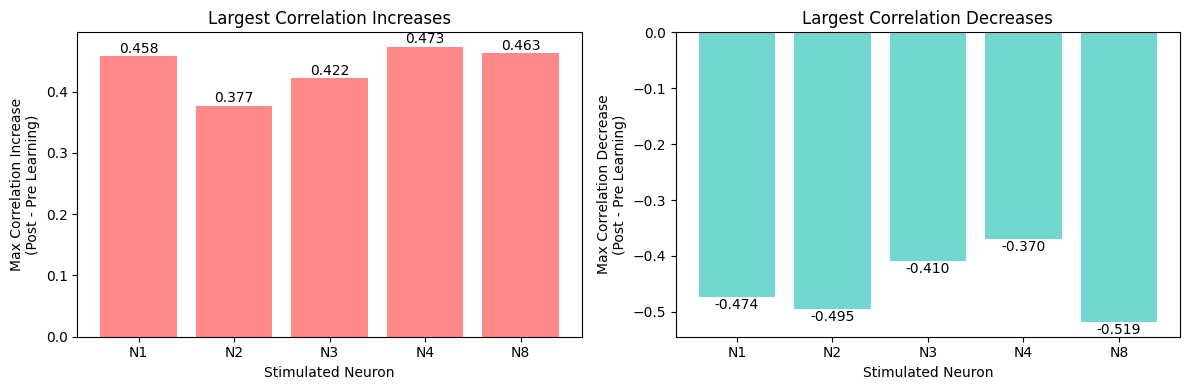

Summary:
Range of max increases: 0.377 to 0.473
Range of max decreases: -0.370 to -0.519


In [56]:
# Run the analysis and collect data for plotting
stimulated_neurons = list(common_neurons)[:5]  # Select first 5 neurons for analysis
max_increases = []  # Store maximum correlation increases for each stimulated neuron
max_decreases = []  # Store maximum correlation decreases for each stimulated neuron

for target_neuron in stimulated_neurons:
    # Get all trials where this specific neuron was stimulated
    pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
    post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]
    
    # Calculate correlation matrices for pre and post learning periods
    correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
    
    # Calculate change in correlations (post - pre)
    correlation_diff = correlations_post - correlations_pre
    
    # Get upper triangle to avoid counting each pair twice and exclude diagonal
    upper_triangle = np.triu(correlation_diff, k=1)
    
    # Find maximum positive and negative changes across all neuron pairs
    max_increases.append(np.max(upper_triangle))  # Largest correlation increase
    max_decreases.append(np.min(upper_triangle))  # Largest correlation decrease

# Create the plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left panel: Max increases
ax1.bar([f'N{n}' for n in stimulated_neurons], max_increases, color='#FF6B6B', alpha=0.8)
ax1.set_ylabel('Max Correlation Increase\n(Post - Pre Learning)')
ax1.set_title('Largest Correlation Increases')
ax1.set_xlabel('Stimulated Neuron')

# Add calculation explanation to left plot
#ax1.text(0.02, 0.98, 'Y = max(correlation_post - correlation_pre)\nfor all neuron pairs', 
         #transform=ax1.transAxes, fontsize=8, verticalalignment='top',
         #bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

# Add value labels on bars
for i, v in enumerate(max_increases):
    ax1.text(i, v + 0.001, f'{v:.3f}', ha='center', va='bottom')

# Right panel: Max decreases
ax2.bar([f'N{n}' for n in stimulated_neurons], max_decreases, color='#4ECDC4', alpha=0.8)
ax2.set_ylabel('Max Correlation Decrease\n(Post - Pre Learning)')
ax2.set_title('Largest Correlation Decreases')
ax2.set_xlabel('Stimulated Neuron')

# Add calculation explanation to right plot
#ax2.text(0.02, 0.04, 'Y = min(correlation_post - correlation_pre)\nfor all neuron pairs', 
         #transform=ax2.transAxes, fontsize=8, verticalalignment='bottom',
         #bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8))

# Add value labels on bars
for i, v in enumerate(max_decreases):
    ax2.text(i, v - 0.001, f'{v:.3f}', ha='center', va='top')

plt.tight_layout()
plt.show()

print("Summary:")
print(f"Range of max increases: {min(max_increases):.3f} to {max(max_increases):.3f}")
print(f"Range of max decreases: {max(max_decreases):.3f} to {min(max_decreases):.3f}")

In [81]:
# Run the analysis for all neurons
stimulated_neurons = list(common_neurons)
all_correlation_changes = {}

for i, target_neuron in enumerate(stimulated_neurons):
   print(f"Processing neuron {target_neuron} ({i+1}/{len(stimulated_neurons)})")
   
   pre_neuron_trials = pre_trials[pre_trials['closest_roi'] == target_neuron]
   post_neuron_trials = post_trials[post_trials['closest_roi'] == target_neuron]
   
   correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
       dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
   
   correlation_diff = correlations_post - correlations_pre
   upper_triangle = np.triu(correlation_diff, k=1)
   all_changes = upper_triangle[upper_triangle != 0]
   all_correlation_changes[target_neuron] = all_changes

# Create plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Combined histogram of all changes
all_changes_combined = np.concatenate(list(all_correlation_changes.values()))
ax1.hist(all_changes_combined, bins=100, alpha=0.7, color='gray')
ax1.set_xlabel('Correlation Change (Post - Pre)')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of All Correlation Changes')
ax1.axvline(x=0, color='red', linestyle='--', alpha=0.7)

# Box plot for all neurons
data_for_boxplot = [changes for changes in all_correlation_changes.values()]
ax2.boxplot(data_for_boxplot)
ax2.set_xlabel('Stimulated Neuron Index')
ax2.set_ylabel('Correlation Change (Post - Pre)')
ax2.set_title('Distribution Summary: All Neurons')
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.7)

# Show fewer x-axis labels
neuron_ids = list(all_correlation_changes.keys())
ax2.set_xticks(range(0, len(neuron_ids), 10))
ax2.set_xticklabels([f'N{neuron_ids[i]}' for i in range(0, len(neuron_ids), 10)], rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics
print(f"Total correlation changes analyzed: {len(all_changes_combined)}")
print(f"Mean change: {np.mean(all_changes_combined):.4f}")
print(f"Median change: {np.median(all_changes_combined):.4f}")
print(f"Standard deviation: {np.std(all_changes_combined):.4f}")

Processing neuron 256 (1/50)


NameError: name 'pre_trials' is not defined

In [2]:
data_for_boxplot

NameError: name 'data_for_boxplot' is not defined

BCI data directory: /data/brain-computer-interface

Session directory: /data/brain-computer-interface/single-plane-ophys_754303_2025-01-27_20-01-31_processed_2025-08-07_06-00-10

NWB file: single-plane-ophys_754303_2025-01-27_20-01-31_behavior_nwb
NWB path: /data/brain-computer-interface/single-plane-ophys_754303_2025-01-27_20-01-31_processed_2025-08-07_06-00-10/single-plane-ophys_754303_2025-01-27_20-01-31_behavior_nwb


/opt/conda/lib/python3.10/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


All threshold files for mouse 754303: ['single-plane-ophys_754303_2025-01-27', 'single-plane-ophys_754303_2025-01-23', 'single-plane-ophys_754303_2025-01-29', 'single-plane-ophys_754303_2025-01-31', 'single-plane-ophys_754303_2025-02-03']

Found threshold file at: /data/bci-thresholds/single-plane-ophys_754303_2025-01-27
total difference in dataframes: 5
Pre-learning trials: 1044
Post-learning trials: 1054
Neurons stimulated in both phases: 50
Full session dff_traces shape: (231103, 2935)
Clean dff_traces shape: (231103, 2786)
Processing neuron 256 (1/50)
Processing neuron 1 (2/50)
Processing neuron 2 (3/50)
Processing neuron 1668 (4/50)
Processing neuron 1029 (5/50)
Processing neuron 2055 (6/50)
Processing neuron 8 (7/50)
Processing neuron 519 (8/50)
Processing neuron 396 (9/50)
Processing neuron 2190 (10/50)
Processing neuron 146 (11/50)
Processing neuron 1049 (12/50)
Processing neuron 30 (13/50)
Processing neuron 31 (14/50)
Processing neuron 544 (15/50)
Processing neuron 289 (16/50)

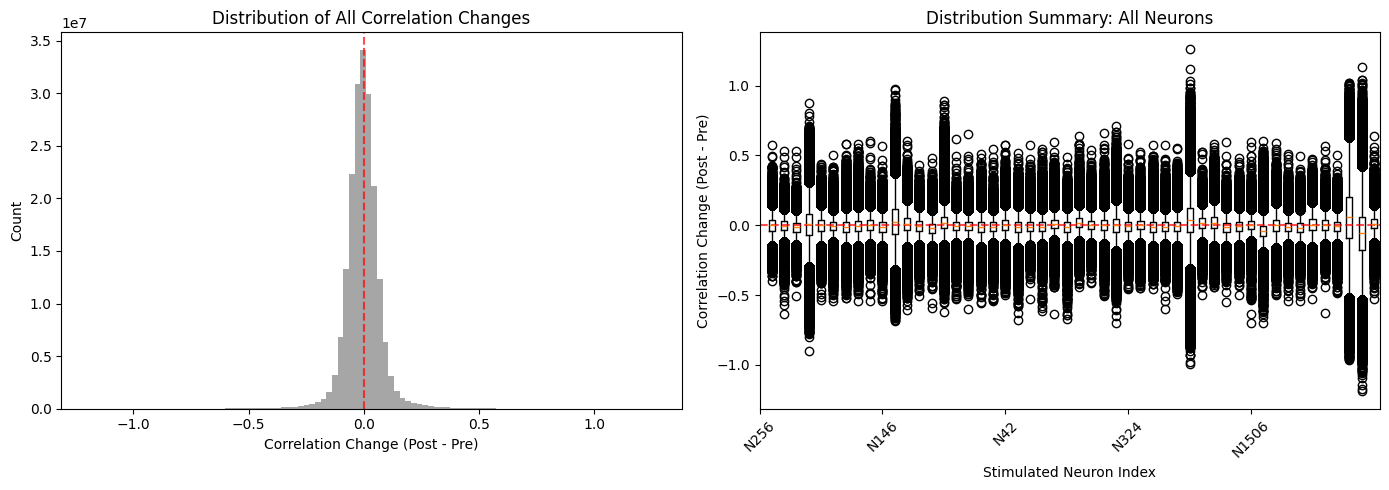

Total correlation changes analyzed: 193975250
Mean change: -0.0032
Median change: -0.0039
Standard deviation: 0.0738


In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Load and filter data for specific subject
metadata = load.load_filtered_metadata()
target_subject_id = 754303 
subject_sessions754303 = metadata[metadata['subject_id'] == target_subject_id]
sesh_zero = subject_sessions754303['name'].values[1]
data = load.load_session_data(sesh_zero)
photostim = data['nwb_file'].stimulus["PhotostimTrials"].to_dataframe()

# Separate the two phases
photostim_trials = photostim[photostim['stimulus_name'] == 'photostim'].copy()
photostim_post_trials = photostim[photostim['stimulus_name'] == 'photostim_post'].copy()
photostim_trials = photostim_trials.reset_index(drop=True)
photostim_post_trials = photostim_post_trials.reset_index(drop=True)

print(f"Pre-learning trials: {len(photostim_trials)}")
print(f"Post-learning trials: {len(photostim_post_trials)}")

# Find common neurons
pre_neurons = set(photostim_trials['closest_roi'])
post_neurons = set(photostim_post_trials['closest_roi'])
common_neurons = pre_neurons.intersection(post_neurons)

print(f"Neurons stimulated in both phases: {len(common_neurons)}")

# Get neural activity data
dff_traces = data['dff_traces']
print(f"Full session dff_traces shape: {dff_traces.shape}")

# Clean the data (remove NaN neurons)
nan_neurons = np.isnan(dff_traces).any(axis=0)
valid_neurons = ~nan_neurons
valid_neuron_indices = np.where(valid_neurons)[0]
dff_traces_clean = dff_traces[:, valid_neuron_indices]

print(f"Clean dff_traces shape: {dff_traces_clean.shape}")

# Define correlation function
def correlation_prepost_stimulation(dff_traces_clean, pre_trials, post_trials, stimulated_neuron_id, show_plot=False):
    # Combine all pre-learning trials
    pre_data_list = []
    for _, trial in pre_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        pre_data_list.append(trial_dff)
    dff_pre = np.concatenate(pre_data_list, axis=1)
    
    # Combine all post-learning trials  
    post_data_list = []
    for _, trial in post_trials.iterrows():
        trial_dff = dff_traces_clean[trial['start_frame']:trial['stop_frame'], :].T
        post_data_list.append(trial_dff)
    dff_post = np.concatenate(post_data_list, axis=1)
    
    # Calculate correlation matrices
    correlations_pre = np.corrcoef(dff_pre)
    correlations_post = np.corrcoef(dff_post)
    
    return correlations_pre, correlations_post, None

# Run the analysis for all neurons
stimulated_neurons = list(common_neurons)
all_correlation_changes = {}

for i, target_neuron in enumerate(stimulated_neurons):
    print(f"Processing neuron {target_neuron} ({i+1}/{len(stimulated_neurons)})")
    
    pre_neuron_trials = photostim_trials[photostim_trials['closest_roi'] == target_neuron]
    post_neuron_trials = photostim_post_trials[photostim_post_trials['closest_roi'] == target_neuron]
    
    correlations_pre, correlations_post, p_val = correlation_prepost_stimulation(
        dff_traces_clean, pre_neuron_trials, post_neuron_trials, target_neuron, show_plot=False)
    
    correlation_diff = correlations_post - correlations_pre
    upper_triangle = np.triu(correlation_diff, k=1)
    all_changes = upper_triangle[upper_triangle != 0]
    all_correlation_changes[target_neuron] = all_changes

# Create plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Combined histogram of all changes
all_changes_combined = np.concatenate(list(all_correlation_changes.values()))
ax1.hist(all_changes_combined, bins=100, alpha=0.7, color='gray')
ax1.set_xlabel('Correlation Change (Post - Pre)')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of All Correlation Changes')
ax1.axvline(x=0, color='red', linestyle='--', alpha=0.7)

# Box plot for all neurons
data_for_boxplot = [changes for changes in all_correlation_changes.values()]
ax2.boxplot(data_for_boxplot)
ax2.set_xlabel('Stimulated Neuron Index')
ax2.set_ylabel('Correlation Change (Post - Pre)')
ax2.set_title('Distribution Summary: All Neurons')
ax2.axhline(y=0, color='red', linestyle='--', alpha=0.7)

# Show fewer x-axis labels
neuron_ids = list(all_correlation_changes.keys())
ax2.set_xticks(range(0, len(neuron_ids), 10))
ax2.set_xticklabels([f'N{neuron_ids[i]}' for i in range(0, len(neuron_ids), 10)], rotation=45)

plt.tight_layout()
plt.show()

# Summary statistics
print(f"Total correlation changes analyzed: {len(all_changes_combined)}")
print(f"Mean change: {np.mean(all_changes_combined):.4f}")
print(f"Median change: {np.median(all_changes_combined):.4f}")
print(f"Standard deviation: {np.std(all_changes_combined):.4f}")